# Рекомендательная система фильмов

Ноутбук строит несколько подходов к рекомендациям:
1. топ популярных фильмов (взвешенный рейтинг);
2. похожие фильмы по оценкам зрителей (item-based collaborative filtering);
3. похожие фильмы по жанрам и году (content-based).

Данные: `movies.csv`, `ratings.csv`.


## 1. Импорт библиотек


In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="muted")
%matplotlib inline

## 2. Загрузка данных

- `movies.csv` — каталог фильмов (id, название, год, жанры)
- `ratings.csv` — оценки пользователей (userId, movieId, rating)


In [3]:
movies = pd.read_csv("data/movies.csv")
ratings = pd.read_csv("data/ratings.csv")

print("movies :", movies.shape)
print("ratings:", ratings.shape)

movies : (9742, 6)
ratings: (100836, 4)


In [4]:
movies.head()

,movieId,imdbId,tmdbId,title,year,genres
0,1,tt0114709,862.000,Toy Story (1995),1995.000,Adventure|Animation|Children|Comedy|Fantasy
1,2,tt0113497,8844.000,Jumanji (1995),1995.000,Adventure|Children|Fantasy
2,3,tt0113228,15602.000,Grumpier Old Men (1995),1995.000,Comedy|Romance
3,4,tt0114885,31357.000,Waiting to Exhale (1995),1995.000,Comedy|Drama|Romance
4,5,tt0113041,11862.000,Father of the Bride Part II (1995),1995.000,Comedy


In [5]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.000,964982703
1,1,3,4.000,964981247
2,1,6,4.000,964982224
3,1,47,5.000,964983815
4,1,50,5.000,964982931


## 3. Объединение и базовая очистка


In [6]:
df = ratings.merge(movies, on="movieId", how="inner")
df = df.drop_duplicates(["userId", "movieId"])

print("строк после объединения:", len(df))
print("пользователей:", df.userId.nunique())
print("фильмов с оценками:", df.movieId.nunique())
df.head()

строк после объединения: 100836
пользователей: 610
фильмов с оценками: 9724


,userId,movieId,rating,timestamp,imdbId,tmdbId,title,year,genres
0,1,1,4.000,964982703,tt0114709,862.000,Toy Story (1995),1995.000,Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.000,964981247,tt0113228,15602.000,Grumpier Old Men (1995),1995.000,Comedy|Romance
2,1,6,4.000,964982224,tt0113277,949.000,Heat (1995),1995.000,Action|Crime|Thriller
3,1,47,5.000,964983815,tt0114369,807.000,Seven (a.k.a. Se7en) (1995),1995.000,Mystery|Thriller
4,1,50,5.000,964982931,tt0114814,629.000,"Usual Suspects, The (1995)",1995.000,Crime|Mystery|Thriller


In [7]:
print("пропуски:")
print(df.isna().sum())
print("\nраспределение оценок:")
print(df.rating.value_counts().sort_index())

пропуски:
userId        0
movieId       0
rating        0
timestamp     0
imdbId        0
tmdbId       13
title         0
year         18
genres        0
dtype: int64

распределение оценок:
rating
0.500     1370
1.000     2811
1.500     1791
2.000     7551
2.500     5550
3.000    20047
3.500    13136
4.000    26818
4.500     8551
5.000    13211
Name: count, dtype: int64


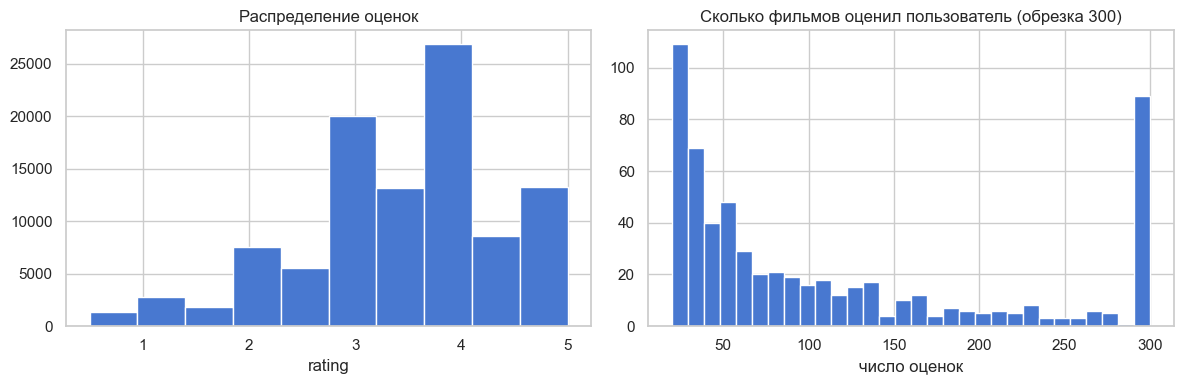

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.rating.hist(bins=10, ax=axes[0], edgecolor="white")
axes[0].set_title("Распределение оценок")
axes[0].set_xlabel("rating")

df.groupby("userId").size().clip(upper=300).hist(bins=30, ax=axes[1], edgecolor="white")
axes[1].set_title("Сколько фильмов оценил пользователь (обрезка 300)")
axes[1].set_xlabel("число оценок")
plt.tight_layout()
plt.show()

## 4. Популярность: взвешенный рейтинг

Обычное среднее обманывает: фильм с одной оценкой 5.0 формально лучше фильма с тысячей оценок 4.6.
Используем формулу Bayesian average (как у IMDb):

$$w = \frac{v \cdot R + m \cdot C}{v + m}$$

- $v$ — число оценок фильма
- $R$ — средняя оценка фильма
- $m$ — порог доверия (90-й перцентиль числа оценок)
- $C$ — средняя оценка по всем фильмам


In [9]:
stats = (
    df.groupby(["movieId", "title", "genres"], as_index=False)
      .agg(avg_rating=("rating", "mean"), count_rating=("rating", "count"))
)

v = stats["count_rating"]
R = stats["avg_rating"]
m = v.quantile(0.90)
C = R.mean()
stats["w_score"] = (v * R + m * C) / (v + m)

print(f"m (порог) = {m:.0f},  C (глобальное среднее) = {C:.3f}")
stats.sort_values("w_score", ascending=False).head(10)

m (порог) = 27,  C (глобальное среднее) = 3.262


,movieId,title,genres,avg_rating,count_rating,w_score
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337
659,858,"Godfather, The (1972)",Crime|Drama,4.289,192,4.162
2224,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,4.162
224,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137
46,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.238,204,4.124
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122
461,527,Schindler's List (1993),Drama|War,4.225,220,4.120
1938,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,4.110
897,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,4.216,211,4.108
314,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096


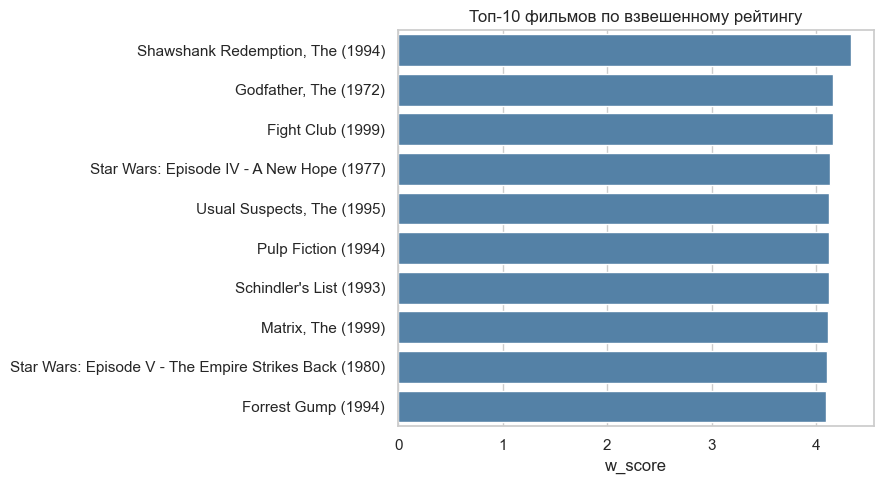

In [10]:
top10 = stats.sort_values("w_score", ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=top10, x="w_score", y="title", color="steelblue")
plt.title("Топ-10 фильмов по взвешенному рейтингу")
plt.xlabel("w_score")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [12]:
def popular_by_genre(genre, n=10):
    mask = stats.genres.str.split("|").apply(lambda g: genre in g)
    return (
        stats[mask]
        .sort_values("w_score", ascending=False)
        .head(n)[["title", "genres", "avg_rating", "count_rating", "w_score"]]
        .reset_index(drop=True)
    )

popular_by_genre("Comedy")

,title,genres,avg_rating,count_rating,w_score
0,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122
1,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096
2,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,4.232,142,4.077
3,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.268,97,4.049
4,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",Comedy|Romance,4.183,120,4.014
5,Monty Python and the Holy Grail (1975),Adventure|Comedy|Fantasy,4.162,136,4.013
6,Fargo (1996),Comedy|Crime|Drama|Thriller,4.116,181,4.005
7,Snatch (2000),Comedy|Crime|Thriller,4.156,93,3.955
8,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.148,88,3.940
9,Back to the Future (1985),Adventure|Comedy|Sci-Fi,4.038,171,3.932


In [13]:
popular_by_genre("Sci-Fi")

,title,genres,avg_rating,count_rating,w_score
0,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137
1,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,4.110
2,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,4.216,211,4.108
3,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.138,196,4.032
4,Eternal Sunshine of the Spotless Mind (2004),Drama|Romance|Sci-Fi,4.160,131,4.007
5,Blade Runner (1982),Action|Sci-Fi|Thriller,4.101,124,3.951
6,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,4.066,143,3.939
7,Back to the Future (1985),Adventure|Comedy|Sci-Fi,4.038,171,3.932
8,Terminator 2: Judgment Day (1991),Action|Sci-Fi,3.971,224,3.895
9,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi,4.058,104,3.894


## 5. Коллаборативная фильтрация (item-based)

Идея: фильмы похожи, если их оценивают одни и те же люди похожим образом.

Шаги:
1. оставляем активных пользователей (чтобы матрица была плотнее);
2. строим матрицу user × movie;
3. считаем cosine-сходство между фильмами;
4. по названию фильма возвращаем ближайших соседей.


In [15]:
MIN_USER_RATINGS = 50
active_users = df.userId.value_counts()
active_users = active_users[active_users >= MIN_USER_RATINGS].index
cf_df = df[df.userId.isin(active_users)].copy()

MIN_MOVIE_RATINGS = 20
popular_movies = cf_df.movieId.value_counts()
popular_movies = popular_movies[popular_movies >= MIN_MOVIE_RATINGS].index
cf_df = cf_df[cf_df.movieId.isin(popular_movies)]

print("для CF: пользователей", cf_df.userId.nunique(),
      "| фильмов", cf_df.movieId.nunique(),
      "| оценок", len(cf_df))

для CF: пользователей 385 | фильмов 1247 | оценок 61091


In [16]:
pivot = cf_df.pivot_table(index="userId", columns="title", values="rating")
pivot = pivot.fillna(0)
print("размер матрицы:", pivot.shape)
pivot.iloc[:5, :5]

размер матрицы: (385, 1247)


title,(500) Days of Summer (2009),10 Things I Hate About You (1999),101 Dalmatians (1996),101 Dalmatians (One Hundred and One Dalmatians) (1961),12 Angry Men (1957)
userId,,,,,
1,0.000,0.000,0.000,0.000,0.000
4,0.000,0.000,0.000,0.000,5.000
6,0.000,0.000,0.000,0.000,0.000
7,0.000,0.000,0.000,0.000,0.000
10,0.000,0.000,0.000,0.000,0.000


In [17]:
X = pivot.T.values.astype(np.float64)
norms = np.linalg.norm(X, axis=1, keepdims=True)
norms[norms == 0] = 1.0
X = X / norms
similarity = X @ X.T  # (n_movies × n_movies)

movie_titles = pivot.columns.to_list()
title_to_idx = {t: i for i, t in enumerate(movie_titles)}
print("матрица сходства:", similarity.shape)

матрица сходства: (1247, 1247)


In [18]:
def find_title(query):
    query = query.strip()
    matches = [t for t in movie_titles if query.lower() in t.lower()]
    if not matches:
        raise ValueError(f"Фильм «{query}» не найден в CF-матрице")
    counts = cf_df.groupby("title").size()
    matches = sorted(matches, key=lambda t: counts.get(t, 0), reverse=True)
    return matches[0]


def recommend_collab(query, n=10):
    title = find_title(query)
    idx = title_to_idx[title]
    scores = similarity[idx].copy()
    scores[idx] = -1
    order = np.argsort(-scores)[:n]

    rows = []
    for j in order:
        t = movie_titles[j]
        meta = stats[stats.title == t].head(1)
        rows.append({
            "title": t,
            "genres": meta.genres.values[0] if len(meta) else "",
            "avg_rating": float(meta.avg_rating.values[0]) if len(meta) else None,
            "count_rating": int(meta.count_rating.values[0]) if len(meta) else 0,
            "similarity": float(scores[j]),
        })
    print("Запрос:", title)
    return pd.DataFrame(rows)

recommend_collab("Toy Story")

Запрос: Toy Story (1995)


,title,genres,avg_rating,count_rating,similarity
0,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,3.750,238,0.659
1,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,0.639
2,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.861,97,0.624
3,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,0.616
4,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,3.868,170,0.614
5,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.138,196,0.609
6,Apollo 13 (1995),Adventure|Drama|IMAX,3.846,201,0.608
7,Groundhog Day (1993),Comedy|Fantasy|Romance,3.944,143,0.600
8,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,0.599
9,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure,4.207,200,0.599


In [19]:
recommend_collab("Matrix")

Запрос: Matrix, The (1999)


,title,genres,avg_rating,count_rating,similarity
0,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,0.767
1,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,4.216,211,0.738
2,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.138,196,0.718
3,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,0.715
4,Saving Private Ryan (1998),Action|Drama|War,4.146,188,0.714
5,"Sixth Sense, The (1999)",Drama|Horror|Mystery,3.894,179,0.702
6,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.106,198,0.683
7,American Beauty (1999),Drama|Romance,4.056,204,0.682
8,"Lord of the Rings: The Return of the King, The...",Action|Adventure|Drama|Fantasy,4.119,185,0.681
9,Gladiator (2000),Action|Adventure|Drama,3.938,170,0.679


In [20]:
recommend_collab("Godfather")

Запрос: Godfather, The (1972)


,title,genres,avg_rating,count_rating,similarity
0,"Godfather: Part II, The (1974)",Crime|Drama,4.260,129,0.843
1,Goodfellas (1990),Crime|Drama,4.250,126,0.707
2,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,0.645
3,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,0.642
4,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,0.642
5,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,0.639
6,Reservoir Dogs (1992),Crime|Mystery|Thriller,4.202,131,0.637
7,Fargo (1996),Comedy|Crime|Drama|Thriller,4.116,181,0.637
8,One Flew Over the Cuckoo's Nest (1975),Drama,4.203,133,0.637
9,American Beauty (1999),Drama|Romance,4.056,204,0.637


## 6. Контентные рекомендации (жанры + год)

Фильмы представляем бинарным вектором: наличие жанров и десятилетия выхода.
Сходство — cosine между этими векторами. Не зависит от оценок пользователей.


In [21]:
if "year" not in movies.columns:
    movies["year"] = pd.to_numeric(
        movies.title.str.extract(r"\((\d{4})\)\s*$", expand=False),
        errors="coerce",
    )

catalog = movies.drop_duplicates("movieId").set_index("movieId")
catalog["year"] = catalog["year"].astype("Int64")

genre_set = sorted({g for s in catalog.genres.fillna("") for g in s.split("|") if g})
decades = sorted({int(y) // 10 * 10 for y in catalog.year.dropna().astype(int)})
feat_names = genre_set + [f"d{d}" for d in decades]
col_index = {name: i for i, name in enumerate(feat_names)}

mat = np.zeros((len(catalog), len(feat_names)), dtype=np.float32)
id_list = catalog.index.to_list()
id_to_row = {mid: i for i, mid in enumerate(id_list)}

for i, mid in enumerate(id_list):
    row = catalog.loc[mid]
    for g in str(row.genres).split("|"):
        if g in col_index:
            mat[i, col_index[g]] = 1.0
    if pd.notna(row.year):
        key = f"d{int(row.year) // 10 * 10}"
        if key in col_index:
            mat[i, col_index[key]] = 1.0

norms = np.linalg.norm(mat, axis=1, keepdims=True)
norms[norms == 0] = 1.0
content_mat = mat / norms
print("признаков:", len(feat_names), "| фильмов:", content_mat.shape[0])

признаков: 32 | фильмов: 9742


In [23]:
def recommend_content(query, n=10, min_votes=10):
    mask = catalog.title.str.contains(re.escape(query), case=False, na=False)
    found = catalog[mask]
    if found.empty:
        raise ValueError(f"Фильм «{query}» не найден")
    counts = stats.set_index("movieId")["count_rating"]
    found = found.assign(cnt=found.index.map(counts).fillna(0))
    mid = int(found.sort_values("cnt", ascending=False).index[0])
    title = catalog.loc[mid, "title"]

    i = id_to_row[mid]
    sims = content_mat @ content_mat[i]
    sims[i] = -1

    order = np.argsort(-sims)
    rows = []
    for j in order:
        if len(rows) >= n:
            break
        other_id = id_list[j]
        meta = stats[stats.movieId == other_id]
        votes = int(meta.count_rating.values[0]) if len(meta) else 0
        if votes < min_votes:
            continue
        rows.append({
            "title": catalog.loc[other_id, "title"],
            "genres": catalog.loc[other_id, "genres"],
            "year": None if pd.isna(catalog.loc[other_id, "year"]) else int(catalog.loc[other_id, "year"]),
            "avg_rating": float(meta.avg_rating.values[0]) if len(meta) else None,
            "count_rating": votes,
            "similarity": float(sims[j]),
        })
    print("Запрос:", title)
    return pd.DataFrame(rows)

recommend_content("Toy Story")

Запрос: Toy Story (1995)


,title,genres,year,avg_rating,count_rating,similarity
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1999,3.861,97,1.000
1,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1998,3.244,45,1.000
2,Space Jam (1996),Adventure|Animation|Children|Comedy|Fantasy|Sc...,1996,2.708,53,0.926
3,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,1998,3.516,92,0.913
4,"Borrowers, The (1997)",Adventure|Children|Comedy|Fantasy,1997,3.042,12,0.913
5,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,2007,3.024,21,0.833
6,James and the Giant Peach (1996),Adventure|Animation|Children|Fantasy|Musical,1996,3.449,49,0.833
7,"Kid in King Arthur's Court, A (1995)",Adventure|Children|Comedy|Fantasy|Romance,1995,2.600,10,0.833
8,Hercules (1997),Adventure|Animation|Children|Comedy|Musical,1997,3.452,31,0.833
9,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,2016,3.450,10,0.833


In [24]:
recommend_content("Dark Knight")

Запрос: Dark Knight, The (2008)


,title,genres,year,avg_rating,count_rating,similarity
0,Swordfish (2001),Action|Crime|Drama,2001,3.103,34,0.894
1,Batman Begins (2005),Action|Crime|IMAX,2005,3.862,116,0.894
2,"Fast and the Furious: Tokyo Drift, The (Fast a...",Action|Crime|Drama|Thriller,2006,2.091,11,0.800
3,Elektra (2005),Action|Adventure|Crime|Drama,2005,2.050,10,0.800
4,Taken (2008),Action|Crime|Drama|Thriller,2008,3.619,42,0.800
5,Hostage (2005),Action|Crime|Drama|Thriller,2005,3.050,10,0.800
6,Miami Vice (2006),Action|Crime|Drama|Thriller,2006,2.750,10,0.800
7,"Boondock Saints, The (2000)",Action|Crime|Drama|Thriller,2000,4.221,43,0.800
8,Elite Squad (Tropa de Elite) (2007),Action|Crime|Drama|Thriller,2007,4.300,10,0.800
9,Collateral (2004),Action|Crime|Drama|Thriller,2004,3.761,44,0.800


## 7. Сводка

| Подход | На чём основан | Когда полезен |
|--------|----------------|---------------|
| **Популярность (w_score)** | число и средняя оценок | холодный старт, «что сейчас в топе» |
| **По жанру** | w_score внутри жанра | быстрый фильтр «хочу комедию» |
| **Collaborative (cosine)** | похожие профили зрителей | «раз понравился Matrix — посмотри Fight Club» |
| **Content (жанры+год)** | описание фильма | новый фильм без оценок, объяснимые рекомендации |

Функции для дальнейшего использования в API:
- `stats` / сортировка по `w_score` и `popular_by_genre`
- `recommend_collab(title)`
- `recommend_content(title)`
